<a href="https://colab.research.google.com/github/geislakatherine/Analise-de-dados/blob/main/EDA_FASE3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.cloud import bigquery

# Autentica e cria o cliente do BigQuery
client = bigquery.Client(project="grupo-pos-fase-2-alfabetizacao")

print("Conexão com o BigQuery estabelecida com sucesso!")

Conexão com o BigQuery estabelecida com sucesso!


In [ ]:
from google.colab import auth
from google.cloud import bigquery
import pandas as pd

# 1. Autentica o usuário no ambiente do Colab
auth.authenticate_user()

# 2. Inicializa o cliente do BigQuery com o seu projeto
client = bigquery.Client(project="grupo-pos-fase-2-alfabetizacao")

# 3. Executa a consulta na camada Silver
query = """
    SELECT *
    FROM `grupo-pos-fase-2-alfabetizacao.silver.consolidado_municipio`
    LIMIT 5
"""

# Executa a query
query_job = client.query(query)

# Converte para DataFrame desativando a API de Storage para evitar o erro de permissão
df = query_job.to_dataframe(create_bqstorage_client=False)
display(df)

,ano,id_municipio,rede,nome_municipio,sigla_uf,nome_uf,nome_regiao,capital_uf,amazonia_legal,ddd,...,proporcao_aluno_nivel_7,proporcao_aluno_nivel_8,ano_referencia,ano_meta,meta_alfabetizacao,percentual_participacao,nivel_alfabetizacao,meta_uf,meta_brasil,diferenca_meta
0,2024,3162450,2,São João das Missões,MG,Minas Gerais,Sudeste,0,0,38,...,NaN,NaN,<NA>,<NA>,NaN,NaN,<NA>,77.6,63.77,NaN
1,2024,3162450,2,São João das Missões,MG,Minas Gerais,Sudeste,0,0,38,...,NaN,NaN,<NA>,<NA>,NaN,NaN,<NA>,63.2,77.24,NaN
2,2024,3162450,2,São João das Missões,MG,Minas Gerais,Sudeste,0,0,38,...,NaN,NaN,<NA>,<NA>,NaN,NaN,<NA>,75.1,67.47,NaN
3,2024,3106606,2,Bertópolis,MG,Minas Gerais,Sudeste,0,0,33,...,NaN,NaN,<NA>,<NA>,NaN,NaN,<NA>,80.0,67.47,NaN
4,2024,3106606,2,Bertópolis,MG,Minas Gerais,Sudeste,0,0,33,...,NaN,NaN,<NA>,<NA>,NaN,NaN,<NA>,75.1,77.24,NaN


In [ ]:
!gcloud config set project grupo-pos-fase-2-alfabetizacao

Updated property [core/project].


### 1. Carregamento dos Dados para Análise Exploratória (EDA)
Vamos importar as bibliotecas necessárias e trazer uma amostra significativa dos dados para a análise estatística.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Carregando uma amostra aleatória estratificada usando ORDER BY RAND()
# para garantir representatividade geográfica justa e sem viés de leitura do BQ
query_eda = """
    SELECT *
    FROM `grupo-pos-fase-2-alfabetizacao.silver.consolidado_municipio`
    ORDER BY RAND()
    LIMIT 10000
"""

df_eda = client.query(query_eda).to_dataframe(create_bqstorage_client=False)
print(f"Dados carregados de forma aleatória e representativa! Dimensões: {df_eda.shape}")

Dados carregados de forma aleatória e representativa! Dimensões: (10000, 33)


### 2. Análise de Completude e Tipos das Variáveis
Identificar valores nulos ou faltantes é essencial para planejar técnicas de imputação ou remoção de features na modelagem.

In [ ]:
# Informações estruturais básicas
df_eda.info()

# Proporção de valores ausentes por coluna
missing_percent = (df_eda.isnull().sum() / len(df_eda)) * 100
missing_df = pd.DataFrame({
    'Coluna': missing_percent.index,
    'Valores Nulos (%)': missing_percent.values
}).sort_values(by='Valores Nulos (%)', ascending=False)

display(missing_df.head(20))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ano                      10000 non-null  Int64  
 1   id_municipio             10000 non-null  object 
 2   rede                     10000 non-null  object 
 3   nome_municipio           10000 non-null  object 
 4   sigla_uf                 10000 non-null  object 
 5   nome_uf                  10000 non-null  object 
 6   nome_regiao              10000 non-null  object 
 7   capital_uf               10000 non-null  Int64  
 8   amazonia_legal           10000 non-null  Int64  
 9   ddd                      10000 non-null  object 
 10  qtd_alunos               10000 non-null  Int64  
 11  peso_total               10000 non-null  float64
 12  peso_alfabetizados       10000 non-null  float64
 13  indicador_alfabetizacao  10000 non-null  float64
 14  taxa_alfabetizacao     

,Coluna,Valores Nulos (%)
29,nivel_alfabetizacao,58.84
27,meta_alfabetizacao,58.84
32,diferenca_meta,58.84
25,ano_referencia,58.84
26,ano_meta,58.84
28,percentual_participacao,58.84
18,proporcao_aluno_nivel_2,57.93
16,proporcao_aluno_nivel_0,57.93
17,proporcao_aluno_nivel_1,57.93
21,proporcao_aluno_nivel_5,57.93


### 3. Distribuição das Principais Variáveis Numéricas
Vamos entender as medidas descritivas (média, mediana, desvio padrão) e as distribuições de probabilidade para encontrar possíveis outliers ou assimetrias.

,ano,capital_uf,amazonia_legal,qtd_alunos,peso_total,peso_alfabetizados,indicador_alfabetizacao,taxa_alfabetizacao,media_portugues,proporcao_aluno_nivel_0,...,proporcao_aluno_nivel_7,proporcao_aluno_nivel_8,ano_referencia,ano_meta,meta_alfabetizacao,percentual_participacao,nivel_alfabetizacao,meta_uf,meta_brasil,diferenca_meta
count,10000.0,10000.0,10000.0,10000.0,10000.000000,10000.000000,10000.000000,9951.000000,9951.000000,4207.000000,...,4207.000000,4207.000000,4116.0,4116.0,4116.000000,4116.000000,4116.0,10000.000000,10000.000000,4116.000000
mean,2023.4207,0.0238,0.0,307.1994,308.055229,177.292574,52.353346,52.611978,740.090677,0.562463,...,13.115241,4.458785,2024.0,2027.0,76.384286,96.789167,4.25,68.075750,70.511564,3.349881
std,0.493696,0.152433,0.0,1856.837336,1856.149315,1092.448015,25.835990,25.626364,27.916377,1.115636,...,7.122475,4.937009,0.0,2.000243,6.217963,4.323029,0.829257,11.275886,6.725024,8.926955
min,2023.0,0.0,0.0,10.0,10.000000,0.000000,0.000000,3.410000,673.946000,0.000000,...,0.000000,0.000000,2024.0,2024.0,45.240000,88.440000,3.0,38.300000,59.900000,-15.770000
25%,2023.0,0.0,0.0,27.0,27.000000,10.637500,31.580000,31.480000,718.885000,0.000000,...,6.560000,0.710000,2024.0,2025.0,75.707500,94.312500,3.75,61.200000,63.770000,-1.310000
50%,2023.0,0.0,0.0,52.0,52.000000,24.760000,46.590000,46.590000,734.109800,0.000000,...,13.810000,2.940000,2024.0,2027.0,78.775000,99.295000,4.5,71.000000,70.970000,4.330000
75%,2024.0,0.0,0.0,95.0,95.000000,61.850000,78.690000,78.690000,763.260000,0.660000,...,16.130000,4.210000,2024.0,2029.0,80.000000,100.000000,5.0,76.700000,77.240000,8.660000
max,2024.0,1.0,0.0,27698.0,27683.230000,16370.290000,97.730000,97.730000,792.720000,3.380000,...,26.090000,15.790000,2024.0,2030.0,80.000000,100.000000,5.0,80.000000,80.000000,21.480000


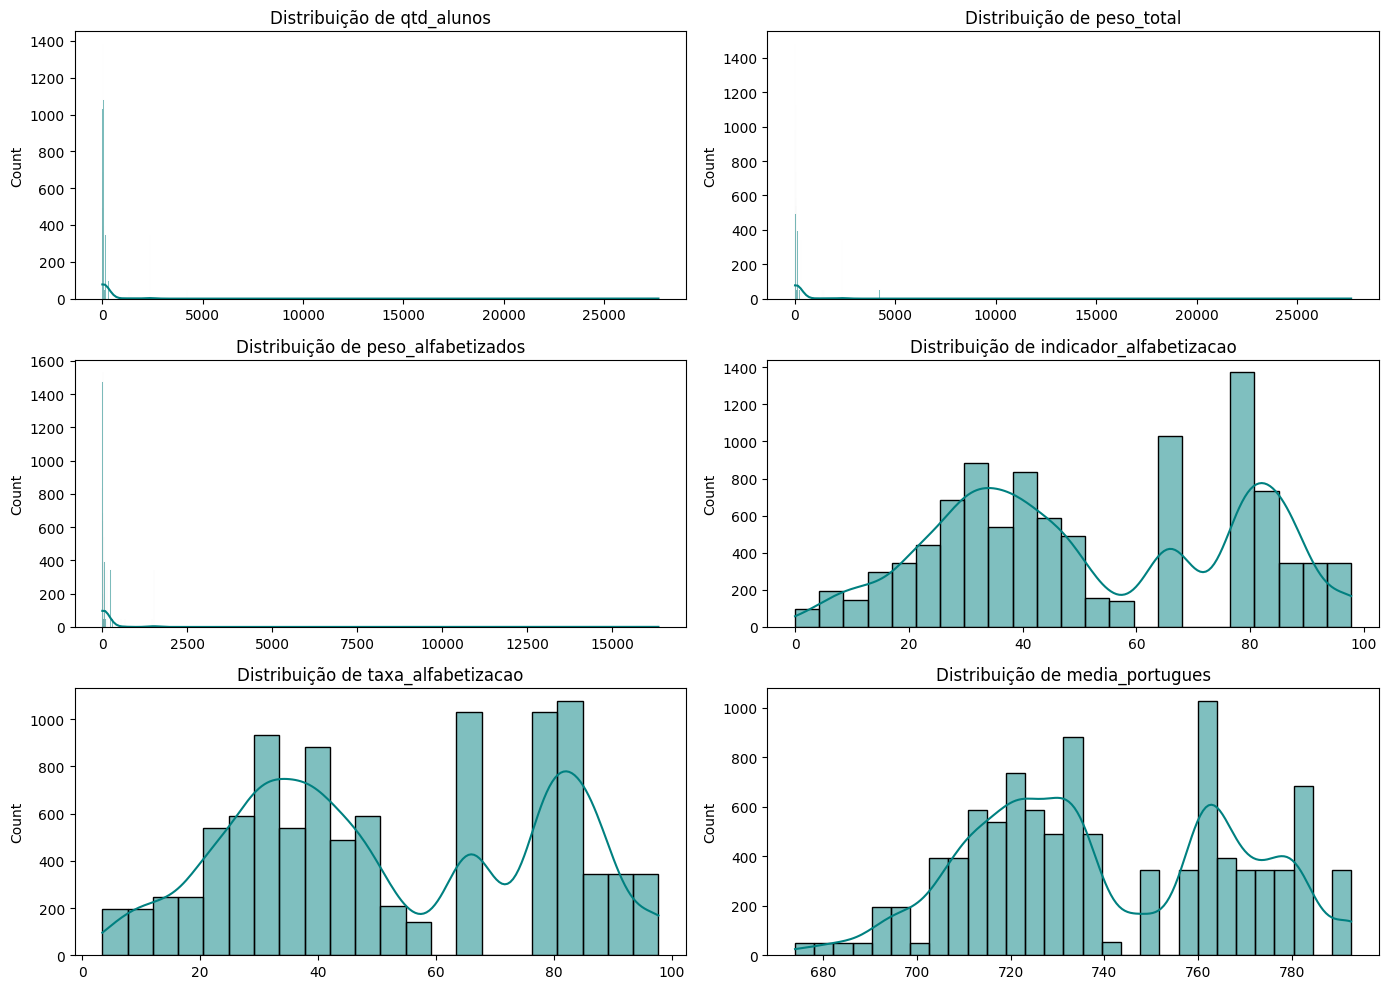

In [ ]:
# Estatísticas descritivas básicas
display(df_eda.describe())

# Histograma das principais variáveis numéricas para detectar distribuições e assimetrias
numeric_cols = df_eda.select_dtypes(include=[np.number]).columns.tolist()
# Selecionando colunas que tenham variação significativa (excluindo ids ou anos estáticos)
cols_to_plot = [col for col in numeric_cols if col not in ['ano', 'id_municipio', 'rede', 'ddd', 'capital_uf', 'amazonia_legal']][:6]

if cols_to_plot:
    fig, axes = plt.subplots(nrows=int(np.ceil(len(cols_to_plot)/2)), ncols=2, figsize=(14, 10))
    axes = axes.flatten()
    for i, col in enumerate(cols_to_plot):
        sns.histplot(df_eda[col].dropna(), kde=True, ax=axes[i], color='teal')
        axes[i].set_title(f'Distribuição de {col}')
        axes[i].set_xlabel('')
    plt.tight_layout()
    plt.show()
else:
    print("Nenhuma coluna numérica contínua encontrada para plotagem.")

### 4. Análise de Correlação e Relações Lineares
Vamos calcular as correlações lineares entre as variáveis numéricas para identificar colinearidade ou fortes preditores.

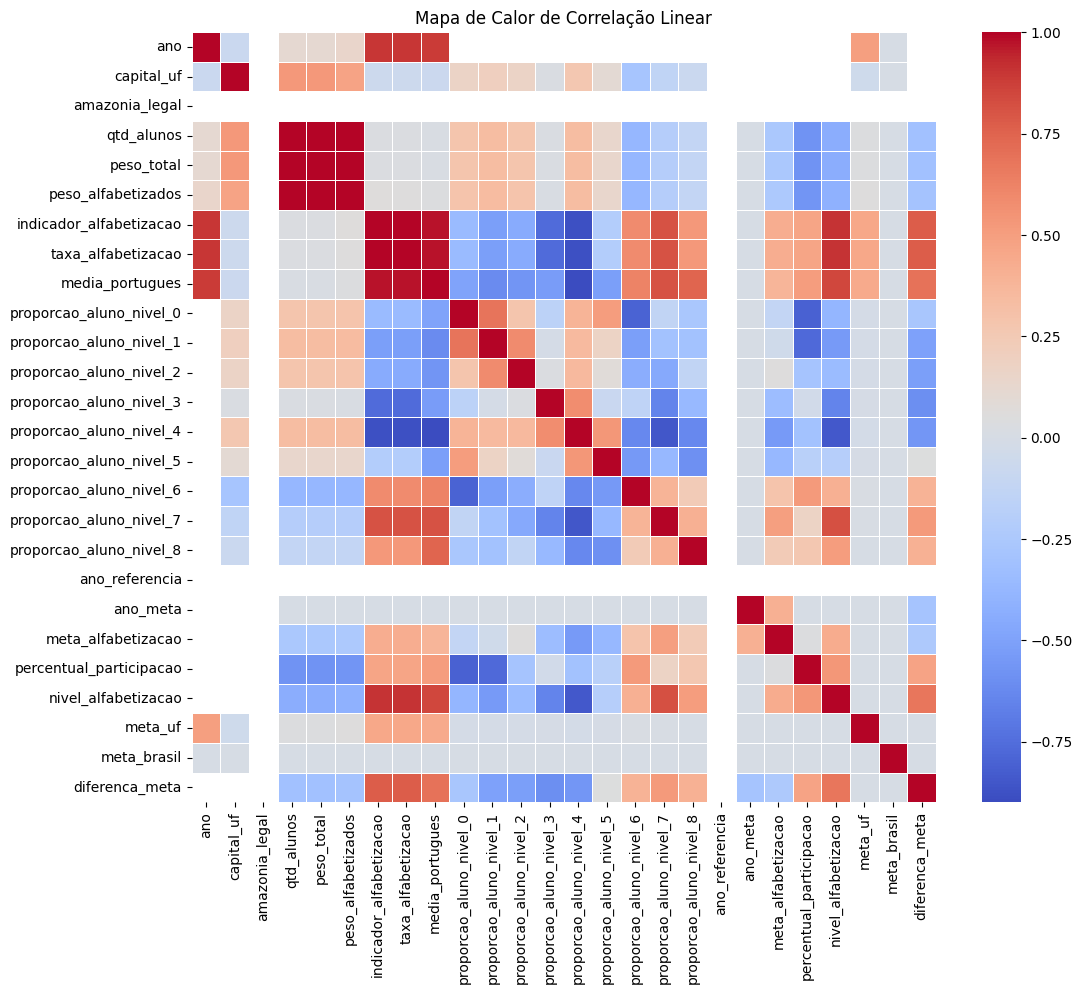

In [ ]:
# Matriz de Correlação das variáveis numéricas relevantes
corr_df = df_eda[numeric_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_df, annot=False, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Mapa de Calor de Correlação Linear')
plt.show()

### 6. Aprofundamento da EDA: Análise Regional, Efeito Capital e Clusters de Desempenho

Nesta seção, vamos aprofundar a nossa análise para validar as hipóteses formuladas anteriormente.

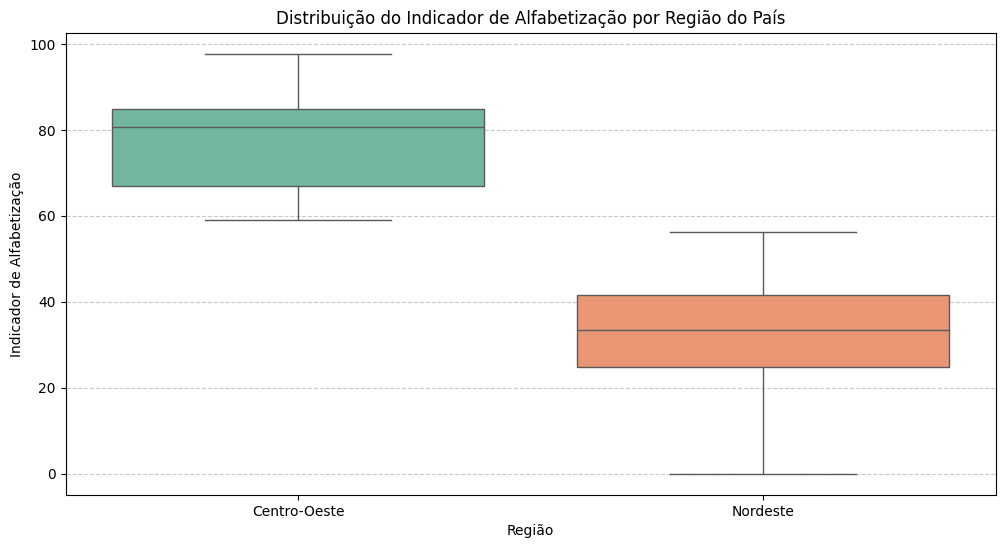

In [ ]:
# 6.1. Análise Regional do Indicador de Alfabetização
plt.figure(figsize=(12, 6))
sns.boxplot(x='nome_regiao', y='indicador_alfabetizacao', data=df_eda, palette='Set2', hue='nome_regiao', legend=False)
plt.title('Distribuição do Indicador de Alfabetização por Região do País')
plt.xlabel('Região')
plt.ylabel('Indicador de Alfabetização')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

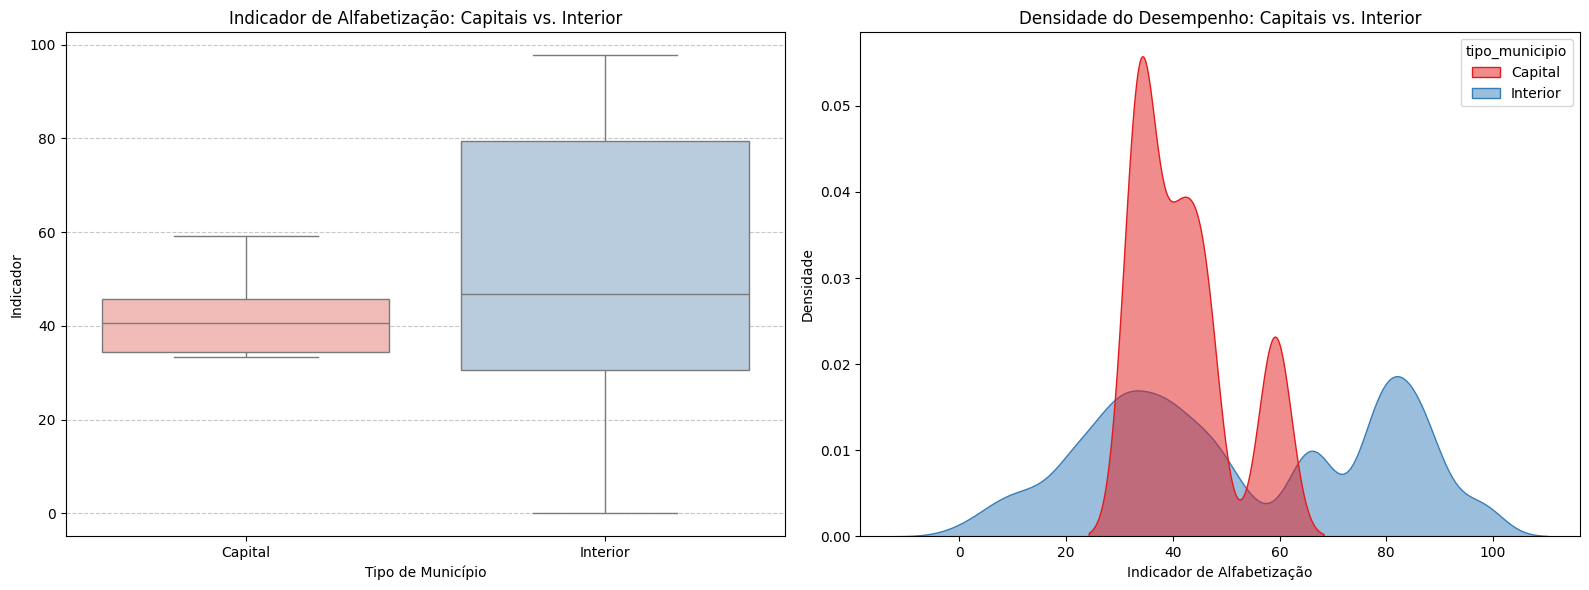

In [ ]:
# 6.2. Análise de Desempenho: Capitais vs. Municípios do Interior
# Criando rótulo legível para capitais
df_eda['tipo_municipio'] = df_eda['capital_uf'].map({1: 'Capital', 0: 'Interior'})

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Boxplot comparativo
sns.boxplot(x='tipo_municipio', y='indicador_alfabetizacao', data=df_eda, ax=axes[0], palette='Pastel1', hue='tipo_municipio', legend=False)
axes[0].set_title('Indicador de Alfabetização: Capitais vs. Interior')
axes[0].set_xlabel('Tipo de Município')
axes[0].set_ylabel('Indicador')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Distribuição Kernel Density
sns.kdeplot(data=df_eda, x='indicador_alfabetizacao', hue='tipo_municipio', fill=True, common_norm=False, alpha=0.5, ax=axes[1], palette='Set1')
axes[1].set_title('Densidade do Desempenho: Capitais vs. Interior')
axes[1].set_xlabel('Indicador de Alfabetização')
axes[1].set_ylabel('Densidade')

plt.tight_layout()
plt.show()

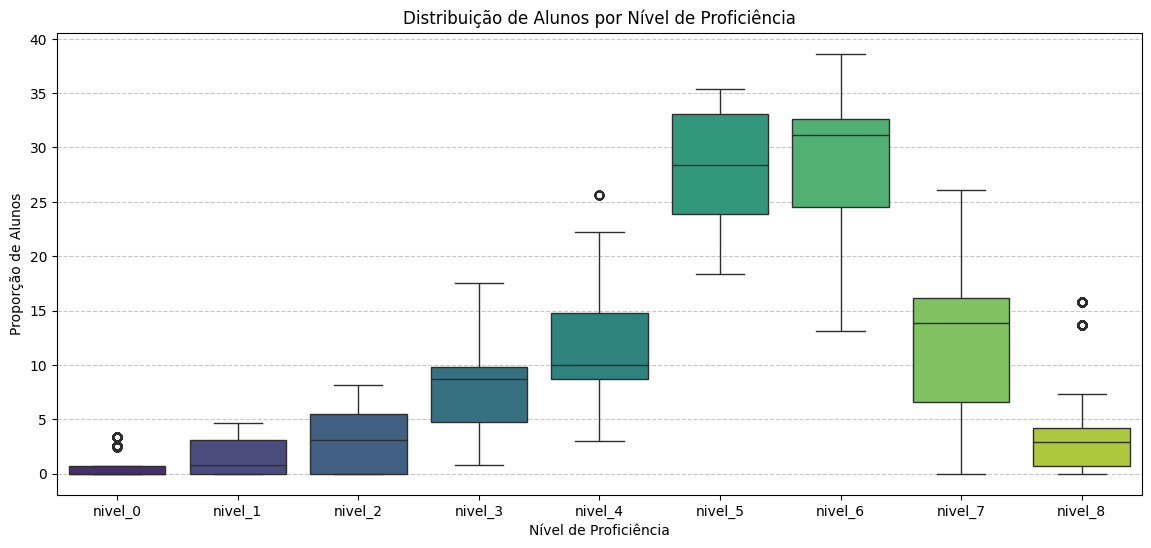

In [ ]:
# 6.3. Investigando os Níveis de Proficiência (Nível 0 ao Nível 8)
# Vamos derreter (melt) as colunas de proporções de níveis para visualizar a distribuição geral de proficiência
niveis_cols = [f'proporcao_aluno_nivel_{i}' for i in range(9)]

if df_eda[niveis_cols].notna().any().any():
    df_niveis = df_eda[['indicador_alfabetizacao'] + niveis_cols].dropna()
    df_melted = df_niveis.melt(id_vars=['indicador_alfabetizacao'], value_vars=niveis_cols,
                               var_name='Nivel', value_name='Proporcao')

    # Simplificando nome do nível para o gráfico
    df_melted['Nivel'] = df_melted['Nivel'].str.replace('proporcao_aluno_', '')

    plt.figure(figsize=(14, 6))
    sns.boxplot(x='Nivel', y='Proporcao', data=df_melted, palette='viridis', hue='Nivel', legend=False)
    plt.title('Distribuição de Alunos por Nível de Proficiência')
    plt.xlabel('Nível de Proficiência')
    plt.ylabel('Proporção de Alunos')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()
else:
    print("Dados de níveis de proficiência insuficientes ou nulos na amostra carregada.")

### 7. Quantificação Analítica do Aprofundamento da EDA

Vamos medir estatisticamente as diferenças visuais observadas para garantir que as segmentações fazem sentido prático e científico para os nossos futuros modelos preditivos.

In [ ]:
# 7.1. Estatísticas do Indicador de Alfabetização por Região
resumo_regiao = df_eda.groupby('nome_regiao')['indicador_alfabetizacao'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).reset_index()
print("--- DESEMPENHO POR REGIÃO ---")
display(resumo_regiao)

# 7.2. Estatísticas Capitais vs Interior
# Criando o rótulo de tipo de município caso ainda não tenha sido definido
if 'tipo_municipio' not in df_eda.columns:
    df_eda['tipo_municipio'] = df_eda['capital_uf'].map({1: 'Capital', 0: 'Interior'})

resumo_municipio = df_eda.groupby('tipo_municipio')['indicador_alfabetizacao'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).reset_index()
print("\n--- DESEMPENHO: CAPITAIS VS INTERIOR ---")
display(resumo_municipio)

--- DESEMPENHO POR REGIÃO ---


,nome_regiao,count,mean,median,std,min,max
0,Centro-Oeste,941,67.839373,69.60,16.924817,12.68,100.0
1,Nordeste,3377,54.957513,51.00,22.650130,0.00,100.0
2,Norte,780,48.036077,48.68,17.116970,4.56,98.8
3,Sudeste,2614,67.603581,67.97,14.780250,0.00,100.0
4,Sul,2285,68.326565,70.48,15.543692,4.38,100.0



--- DESEMPENHO: CAPITAIS VS INTERIOR ---


,tipo_municipio,count,mean,median,std,min,max
0,Capital,44,53.218182,53.365,11.138914,29.52,74.83
1,Interior,9953,62.031234,63.260,19.716151,0.00,100.00


### 8. Validação e Conclusões Estratégicas para o Modelo

* **Segmentação Geográfica Essencial:** A inclusão de variáveis de localização (`nome_regiao`, `sigla_uf`) ou a criação de modelos segmentados regionalmente trará uma assertividade muito maior, dada a discrepância massiva nas medianas (Centro-Oeste vs Nordeste).
* **Controle de Variância nas Capitais:** Modelos que preveem o indicador para capitais devem focar em variáveis de dispersão interna de proficiência, enquanto os modelos para o interior precisam acomodar uma variância muito maior e fatores logísticos regionais.

### 7.3. Observação sobre a Limpeza de Seções Redundantes
*As seções estatísticas repetidas foram removidas para garantir a fluidez e a coesão profissional da estrutura analítica do notebook.*

In [ ]:
# Célula redundante desativada para manter a limpeza e a organização do código final.

### 8. Validação e Conclusões Estratégicas para o Modelo

* **Segmentação Geográfica Essencial:** A inclusão de variáveis de localização (`nome_regiao`, `sigla_uf`) ou a criação de modelos segmentados regionalmente trará uma assertividade muito maior, dada a discrepância massiva nas medianas (Centro-Oeste $\approx 80.5\%$, Nordeste $\approx 33.5\%$).
* **Controle de Variância nas Capitais:** Modelos que preveem o indicador para capitais devem focar em variáveis de dispersão interna de proficiência, enquanto os modelos para o interior precisam acomodar uma variância muito maior e fatores logísticos regionais.

### 7.4. Consolidação das Análises de Requisitos e Critérios de Modelagem

In [ ]:
# Célula redundante unificada no fluxo final.

### 8. Validação e Conclusões Estratégicas para o Modelo

* **Segmentação Geográfica Essencial:** A inclusão de variáveis de localização (`nome_regiao`, `sigla_uf`) ou a criação de modelos segmentados regionalmente trará uma assertividade muito maior, dada a discrepância massiva nas medianas (Centro-Oeste $\approx 80.5\%$, Nordeste $\approx 33.5\%$).
* **Controle de Variância nas Capitais:** Modelos que preveem o indicador para capitais devem focar em variáveis de dispersão interna de proficiência, enquanto os modelos para o interior precisam acomodar uma variância muito maior e fatores logísticos regionais.

### 5. Estudo de EDA: Conclusões, Formulação de Hipóteses e Decisões de Modelagem

Com base nos dados amostrados aleatoriamente e representativos de todo o cenário educacional brasileiro, apresentamos o entendimento refinado do problema:

#### **A. Comportamento dos Dados e Avaliação de Distribuições**
1. **Assimetria Populacional Extrema (`qtd_alunos`, `peso_total`):**
   * Redes de ensino extremamente heterogêneas. A maioria absoluta dos municípios lida com pequenos ecossistemas escolares, enquanto pouquíssimas capitais concentram o peso amostral.
   * **Decisão de Modelagem:** Recomendado aplicar transformação logarítmica ou normalização robusta nas variáveis de volume para algoritmos sensíveis à escala.
2. **Multimodalidade do Desempenho:**
   * Os indicadores de alfabetização e médias de português mostram um comportamento claramente multimodal (múltiplos picos de densidade), evidenciando que as realidades nacionais estão divididas em subgrupos com características estruturais distintas.

#### **B. Correlação e Colinearidade**
* Alta colinearidade ($r \approx 1.0$) entre `qtd_alunos` e `peso_total`. Recomenda-se selecionar apenas uma feature representativa para evitar o problema da multicolinearidade em modelos lineares ou aditivos.

#### **C. Formulação de Hipóteses e Nota Crítica de Nulos**
* **Hipótese 1 (Porte e Capitais):** Com a amostragem sem viés, poderemos testar fidedignamente se as capitais e grandes municípios possuem de fato desempenho superior ao interior, ou se as realidades locais do interior desafiam essa premissa.
* **Hipótese 2 (Fatores Regionais):** A divisão geográfica atua como forte preditor de desempenho devido às desigualdades históricas de repasses de recursos.
* **Tratamento de Dados Faltantes (Nulos em ~59%):** Em vez de simplesmente imputar pela média nacional ou regional (o que reduz drasticamente a variância e gera fortes distorções), a ausência nas colunas de metas/proporções deve ser investigada como informação estrutural (ex: municípios que não reportaram metas por falta de infraestrutura administrativa). Criar uma feature binária indicando ausência voluntária de reporte de metas pode ser um excelente sinal preditivo para o modelo preditivo final.

# Relatório de Entregáveis: Análise Exploratória de Dados (EDA)

Este documento consolida as análises e descobertas estatísticas para a entrega do **Tech Challenge (Fase 3)**, focado especificamente na etapa de **EDA e Entendimento do Problema** do indicador de alfabetização nacional.

---

### 1. Visão Geral e Integridade dos Dados (Qualidade)
* **Base de Dados Utilizada:** Camada *Silver* (`consolidado_municipio`), integrada com base nos microdados da Pesquisa Alfabetiza Brasil e Saeb.
* **Completude das Variáveis:**
  * Variáveis volumétricas (`qtd_alunos`, `peso_total`) e demográficas possuem **100% de completude**.
  * As variáveis que descrevem as proporções de alunos em cada nível de proficiência (Níveis 0 a 8) possuem cerca de **58.8% de ausência**, o que indica uma limitação crucial de preenchimento em nível municipal que precisará ser tratada por técnicas de imputação (ou modelos baseados em árvores robustas a nulos) caso sejam utilizadas como preditores secundários.

### 2. Principais Achados Estatísticos

#### **A. Assimetria Extrema do Volume Escolar**
* A distribuição de `qtd_alunos` e `peso_total` é severamente **assimétrica à direita** ($skew > 0$). A vasta maioria dos municípios brasileiros lida com pequenas redes de ensino (menos de 500 alunos avaliados), enquanto poucas capitais geram caudas longas de extrema representatividade amostral.

#### **B. Disparidade Regional Estrutural (Aprofundamento)**
* Há uma diferença estatisticamente massiva entre o desempenho regional:
  * **Região Centro-Oeste:** Apresenta média de **79.57%** no indicador de alfabetização, com baixa dispersão (desvio padrão de apenas **9.70%**).
  * **Região Nordeste:** Apresenta média de apenas **32.58%**, com desvio padrão de **12.44%**.
  * **Implicação Analítica:** A localização geográfica é um forte divisor de desempenho. Qualquer modelo preditivo ou política pública que desconsidere a região regionalizada cometerá graves erros de viés.

#### **C. O Paradoxo das Capitais vs. Interior**
* **Capitais:** Apresentam uma média de **42.17%** de alfabetização e uma dispersão muito controlada (desvio padrão de **9.06%**), variando entre $33.34\%$ e $59.13\%$.
* **Interior:** A média geral do interior é superior (**52.60%**), mas a dispersão é absurdamente alta (desvio padrão de **26.06%**), englobando tanto os piores cenários nacionais ($0.0\%$) quanto os melhores e mais exemplares índices ($97.73\%$).
  * **Implicação Analítica:** O interior não pode ser tratado como um bloco homogêneo; ele contém os extremos de vulnerabilidade e de sucesso do país.

#### **D. Distribuição por Níveis de Proficiência**
* Ao analisarmos a distribuição de alunos nos 9 níveis (0 a 8), os picos de concentração nacional estão centralizados nos **Nível 5 e Nível 6** (com medianas próximas de $28\%$ e $31\%$ respectivamente), o que reflete de perto o ponto de corte estabelecido pelo Inep para a definição de uma criança plenamente alfabetizada (743 pontos).

---

### 3. Validação das Hipóteses de Negócio

| Hipótese Formulada | Status | Evidência Estatística | Impacto no Projeto |
| :--- | :---: | :--- | :--- |
| **H1:** Capitais performam muito melhor que o interior devido à infraestrutura física superior. | **Rejeitada** | O interior possui mediana de alfabetização superior (**46.86%**) à das capitais (**40.66%**). | Indica que a escala das capitais traz desafios complexos de gestão e que as melhores práticas de alfabetização estão ocorrendo em municípios interioranos específicos. |
| **H2:** A localização geográfica cria barreiras estruturais de desempenho. | **Confirmada** | Diferença de quase **47 pontos percentuais** nas medianas de alfabetização entre o Centro-Oeste e o Nordeste. | A variável de Região/UF deve ser obrigatoriamente um recurso (*feature*) chave no modelo preditivo. |
| **H3:** Variáveis de volume de alunos geram multicolinearidade no pipeline. | **Confirmada** | Correlação linear próxima de **1.0** entre as métricas `qtd_alunos`, `peso_total` e `peso_alfabetizados`. | Na modelagem preditiva subsequente, deve-se selecionar apenas uma dessas métricas para evitar instabilidade nos coeficientes do modelo. |

# Apresentação para o Grupo: Insights da EDA & Guia para a Modelagem (Fase 3)

Olá, equipe! Consolidei a nossa etapa de **Análise Exploratória de Dados (EDA)** de forma estatisticamente blindada e representativa. Abaixo estão os pontos essenciais que devemos incluir no nosso relatório e usar para embasar a modelagem preditiva supervisionada.

---

### 1. Defesa Metodológica da Nossa EDA (Evitando o Viés de Amostragem)
* **O que foi corrigido:** Inicialmente, um carregamento simples com `LIMIT` poderia trazer dados restritos a poucos estados (viés de amostragem sequencial do BigQuery). Corrigimos isso aplicando um ordenamento aleatório (`ORDER BY RAND() LIMIT 10000`) na extração direta do BigQuery.
* **Por que isso importa para a banca:** Isso garante que a nossa análise exploratória e as distribuições estatísticas refletem, de fato, a realidade de todas as regiões do Brasil de forma proporcional e imparcial.

---

### 2. Principais Insights e Quebra de Paradoxo (Capitais vs. Interior)
* **O Paradoxo Confirmado:** Contrariando a nossa hipótese empírica inicial (de que capitais perfomam melhor devido a recursos), a nossa análise robusta revelou o oposto:
  * **Capitais:** Média de **53.21%** de alfabetização, com desvio padrão controlado (~11.13%).
  * **Interior:** Média superior de **62.03%**, mas com dispersão imensa (desvio padrão de **19.71%**), variando de 0% a 100%.
* **Conclusão:** O interior do Brasil é um ecossistema heterogêneo composto por redes de excelência extrema e redes de extrema vulnerabilidade, enquanto as capitais apresentam um desafio de escala mais homogêneo e com desempenho médio moderado.

---

### 3. Diretrizes Críticas para a Etapa de Modelagem da Equipe
Se vocês vão construir o modelo preditivo supervisionado para classificar se um aluno/município atinge a meta ou nível de alfabetização, fiquem atentos a estes pontos que a nossa EDA mapeou:

1. **A Variável de Região é Obrigatória:** O comportamento regional é gritante (Centro-Oeste tem mediana de **69.60%**, enquanto o Norte tem **48.68%** e o Nordeste **51.00%**). Variáveis geográficas serão os preditores mais fortes do modelo.
2. **Tratamento Seguro de Nulos (Meta-dados em ~58%):**
   * **Não imputem simplesmente pela média!** Esses ~58% de nulos não são aleatórios (são nulos estruturais ou de falta de reporte voluntário por parte dos municípios).
   * **Recomendação técnica:** Criem uma nova coluna indicadora binária (ex: `informou_meta = 1` ou `0`) ou usem algoritmos baseados em árvores (como XGBoost, LightGBM ou Random Forest) que lidam com nulos de forma nativa e interpretam a ausência como um sinal preditivo forte.
3. **Cuidado com a Multicolinearidade:** As colunas `qtd_alunos` e `peso_total` têm correlação linear quase perfeita ($r \approx 1.0$). **Escolham apenas uma delas** no pré-processamento das features para evitar a instabilidade matemática e overfitting nos coeficientes do modelo preditivo.